# TradeWise: Stock Strategy Analysis
**Moving Average Crossover (20/50) backtest on the top 20 Nifty 50 stocks**

Flow: Data load -> Cleaning -> Top-20 selection -> Strategy -> Metrics -> Objective Qs -> Subjective Qs -> Recommendations

In [1]:
# Setup: imports and plotting style
import warnings, os
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
os.makedirs("figs", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

INITIAL_CAPITAL = 100000.0   # as per the metric definitions
SHORT_W, LONG_W = 20, 50     # short and long moving average windows
TRADING_DAYS = 252
RF = 0.0                     # risk-free rate assumed 0

Matplotlib is building the font cache; this may take a moment.


## Step 1 - Data Acquisition

In [2]:
# Load the raw dataset and inspect structure
raw = pd.read_csv("combined_nifty_50_data.csv")
print("Raw shape:", raw.shape)
display(raw.head())
display(raw.dtypes.to_frame("dtype").T)
print("\nMissing values per column:")
print(raw.isna().sum())
print("\nStocks in file:", raw["Stock"].nunique())

Raw shape: (238885, 10)


,Date,Open,High,Low,Close,Adj Close,Volume,VWAP,Stock,Price
0,02-07-2002,15.379487,16.343575,15.379487,16.297667,15.277594,664008.0,16.00690967,BHARTI_AIRTEL,NaN
1,03-07-2002,16.527210,16.527210,16.045168,16.136984,15.126969,564071.0,16.236454,BHARTI_AIRTEL,NaN
2,04-07-2002,16.412437,16.641981,16.182894,16.527210,15.492774,1127138.0,16.450695,BHARTI_AIRTEL,NaN
3,05-07-2002,16.091076,16.274712,15.609032,15.700850,14.718133,886627.0,15.86153133,BHARTI_AIRTEL,NaN
4,08-07-2002,15.723804,15.930394,15.494260,15.609032,14.632062,561511.0,15.67789533,BHARTI_AIRTEL,NaN


,Date,Open,High,Low,Close,Adj Close,Volume,VWAP,Stock,Price
dtype,str,float64,float64,float64,float64,float64,float64,str,str,float64



Missing values per column:
Date              1
Open            400
High            400
Low             400
Close           400
Adj Close      4257
Volume         4257
VWAP              1
Stock             0
Price        237507
dtype: int64

Stocks in file: 47


## Step 2 - Data Cleaning
Issues found: (a) one fully blank row (tied to the index series `NIFTY_50_STOCKS`), (b) `NIFTY_50_STOCKS` is an index, not a stock, (c) `Date` is text in dd-mm-yyyy, (d) `VWAP` is text and has a `#VALUE!` error, (e) `Price` is ~99% empty and unused, (f) different stocks have different history lengths.

In [3]:
# Cleaning function: converts types, removes junk rows/columns, sorts and de-duplicates
def clean_data(df):
    d = df.copy()
    d = d.dropna(subset=["Date"])                                   # blank row
    d = d[d["Stock"] != "NIFTY_50_STOCKS"]                          # index, not a stock
    d["Date"] = pd.to_datetime(d["Date"], format="%d-%m-%Y")         # consistent date format
    d["VWAP"] = pd.to_numeric(d["VWAP"], errors="coerce")           # '#VALUE!' -> NaN
    d = d.drop(columns=["Price"])                                    # 99% empty, not needed
    d = d.drop_duplicates(subset=["Date", "Stock"])
    d = d.dropna(subset=["Close"])                                   # no close -> unusable
    d["Volume"] = d["Volume"].fillna(0)
    d["Stock"] = d["Stock"].str.strip()
    return d.sort_values(["Stock", "Date"]).reset_index(drop=True)

df = clean_data(raw)
print("Clean shape:", df.shape, "| Date range:", df.Date.min().date(), "to", df.Date.max().date())

# Restrict to the last 5 years of available data
END = df["Date"].max()
START = END - pd.DateOffset(years=5) + pd.Timedelta(days=1)
df5 = df[(df["Date"] >= START)].copy()
print("5-year window:", START.date(), "to", END.date(), "| rows:", len(df5))

# Sanity check: look for corporate-action style jumps (|daily return| > 50%)
df5["Daily_Return"] = df5.groupby("Stock")["Close"].pct_change()
print("Days with |return| > 50%:", int((df5["Daily_Return"].abs() > 0.5).sum()))
print("Missing values after cleaning:\n", df5[["Open","High","Low","Close","Volume"]].isna().sum().to_dict())

Clean shape: (234628, 9) | Date range: 2000-01-03 to 2023-06-23
5-year window: 2018-06-24 to 2023-06-23 | rows: 56788
Days with |return| > 50%: 0
Missing values after cleaning:
 {'Open': 0, 'High': 0, 'Low': 0, 'Close': 0, 'Volume': 0}


### Selecting the "Top 20" stocks
The file has 47 series. "Top 20" is defined here as the **20 most actively traded stocks** (highest average daily traded value = Close x Volume) over the 5-year window, restricted to stocks with a full history. This favours liquid names where a crossover strategy is realistically executable.

Eligible stocks: 46
Top 20: ['ADANI_ENTERPRISES', 'ADANI_PORTS', 'AXIS_BANK', 'BAJAJ_FINANCE', 'BAJAJ_FINSERV', 'BHARTI_AIRTEL', 'HCL_TECHNOLOIES', 'HDFC_BANK', 'HINDUSTAN UNILEVER', 'ICICI_BANK', 'INDUS INDUSTRIES', 'INFOSYS', 'ITC', 'KOTAK_MAHINDRA', 'MARUTI SUZUKI', 'RELIANCE', 'SBI_BANK', 'TATA CONSULTANCY SERVICES', 'TATA MOTORS', 'TATA STEEL']


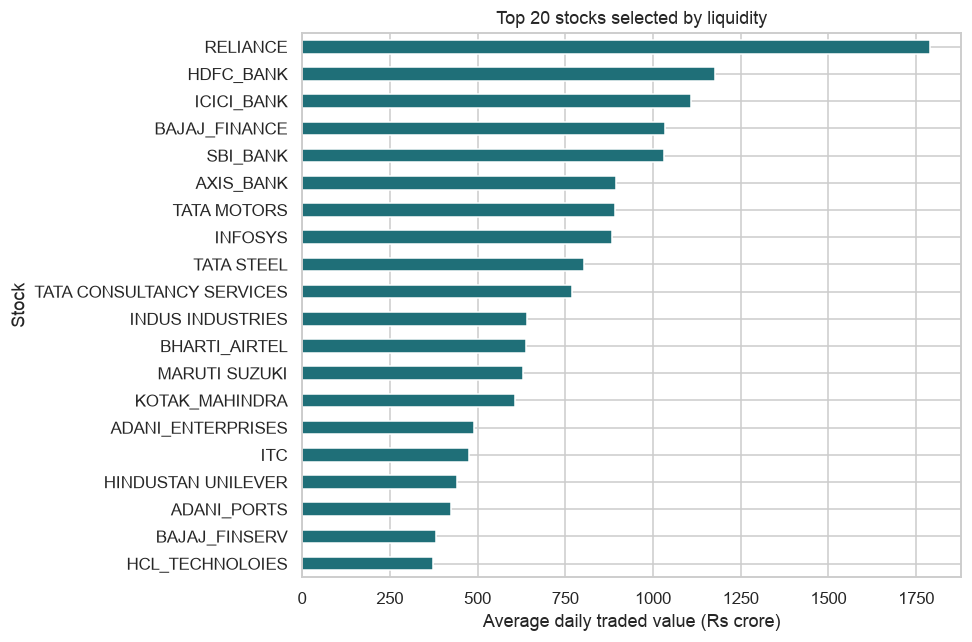

In [4]:
# Top-20 selection by average daily traded value
df5["Traded_Value"] = df5["Close"] * df5["Volume"]
full_len = df5.groupby("Stock")["Date"].count()
eligible = full_len[full_len >= 0.95 * full_len.max()].index          # full-history stocks only
tv = df5[df5.Stock.isin(eligible)].groupby("Stock")["Traded_Value"].mean().sort_values(ascending=False)
top20 = tv.head(20).index.tolist()
print("Eligible stocks:", len(eligible))
print("Top 20:", sorted(top20))

data = df5[df5.Stock.isin(top20)].copy()
fig, ax = plt.subplots(figsize=(9, 6))
(tv.head(20) / 1e7).sort_values().plot.barh(ax=ax, color="#1F6F78")
ax.set_xlabel("Average daily traded value (Rs crore)"); ax.set_title("Top 20 stocks selected by liquidity")
plt.tight_layout(); plt.savefig("figs/top20_selection.png"); plt.show()

## Step 3 - Strategy Implementation
* SMA = 20-day moving average of Close, LMA = 50-day moving average of Close
* **Buy** when SMA crosses above LMA; **Sell** when SMA crosses below LMA
* Long-only. The signal is applied from the **next day** (shift by 1) to avoid look-ahead bias.
* Starting capital Rs 1,00,000; the full amount is invested on a buy and fully exited on a sell.
* MAs are computed on the full history before the window starts so the first signals are valid from day one.

In [5]:
# Function: compute MAs, crossover signals, positions, strategy returns and equity curve for one stock
def apply_strategy(stock_df, full_df_stock):
    """stock_df: 5-year rows of one stock; full_df_stock: complete history used only to warm up the MAs."""
    full = full_df_stock.set_index("Date").copy()
    full["SMA"] = full["Close"].rolling(SHORT_W).mean()
    full["LMA"] = full["Close"].rolling(LONG_W).mean()
    d = full.loc[stock_df["Date"].min():].copy()
    d["Daily_Return"] = d["Close"].pct_change()
    above = (d["SMA"] > d["LMA"]).astype(int)
    d["Signal"] = 0
    d.loc[(above == 1) & (above.shift(1) == 0), "Signal"] = 1       # Buy: SMA crosses above LMA
    d.loc[(above == 0) & (above.shift(1) == 1), "Signal"] = -1      # Sell: SMA crosses below LMA
    d["Position"] = above.shift(1).fillna(0)                        # hold from the next day
    d["Strategy_Return"] = d["Position"] * d["Daily_Return"]
    d["Strategy_Equity"] = INITIAL_CAPITAL * (1 + d["Strategy_Return"].fillna(0)).cumprod()
    d["BuyHold_Equity"] = INITIAL_CAPITAL * (1 + d["Daily_Return"].fillna(0)).cumprod()
    return d

full_hist = {s: df[df.Stock == s] for s in top20}
bt = {s: apply_strategy(data[data.Stock == s], full_hist[s]) for s in top20}
display(bt["RELIANCE"][["Close","SMA","LMA","Signal","Position","Strategy_Equity"]].dropna().iloc[40:50])

,Close,SMA,LMA,Signal,Position,Strategy_Equity
Date,,,,,,
2018-08-21,1235.488770,1171.061987,1076.390888,0,1.0,124167.448185
2018-08-23,1257.529907,1178.912573,1081.785751,0,1.0,126382.597204
2018-08-24,1265.504272,1186.953851,1087.234105,0,1.0,127184.026223
2018-08-27,1279.372803,1195.911444,1092.851854,0,1.0,128577.822869
2018-08-28,1306.614624,1205.280139,1098.890613,0,1.0,131315.644110
2018-08-29,1282.047485,1212.353094,1104.411283,0,1.0,128846.630200
2018-08-30,1262.482910,1216.734064,1109.927000,0,1.0,126880.377320
2018-08-31,1229.990967,1219.175922,1114.333234,0,1.0,123614.915304
2018-09-03,1217.608276,1222.187378,1118.240199,0,1.0,122370.446572


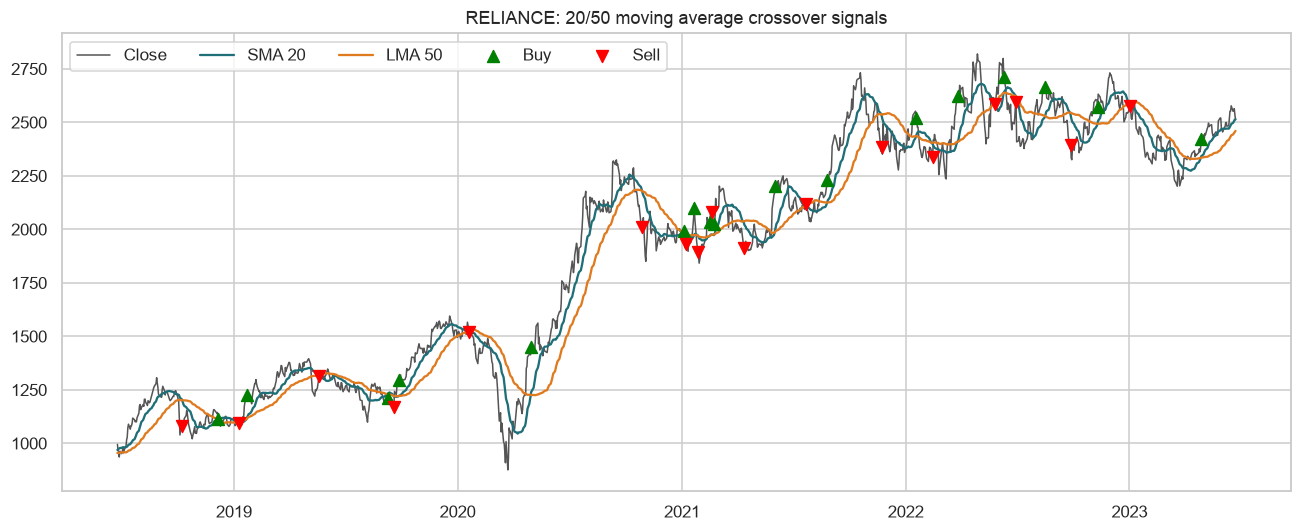

In [6]:
# Visual check of the strategy on one stock (price, SMA, LMA, buy/sell markers)
s = "RELIANCE"; d = bt[s]
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(d.index, d["Close"], label="Close", color="#555", lw=1)
ax.plot(d.index, d["SMA"], label="SMA 20", color="#1F6F78")
ax.plot(d.index, d["LMA"], label="LMA 50", color="#E07A1F")
ax.scatter(d.index[d.Signal == 1], d.loc[d.Signal == 1, "Close"], marker="^", color="green", s=60, label="Buy", zorder=5)
ax.scatter(d.index[d.Signal == -1], d.loc[d.Signal == -1, "Close"], marker="v", color="red", s=60, label="Sell", zorder=5)
ax.set_title(f"{s}: 20/50 moving average crossover signals"); ax.legend(ncol=5)
plt.tight_layout(); plt.savefig("figs/signals_reliance.png"); plt.show()

## Step 4 - Performance Metrics

In [7]:
# Function: build the trade log (entry/exit) from signals; an open trade is closed at the last price
def trade_log(d):
    trades, entry_px, entry_dt = [], None, None
    for dt, row in d.iterrows():
        if row["Signal"] == 1 and entry_px is None:
            entry_px, entry_dt = row["Close"], dt
        elif row["Signal"] == -1 and entry_px is not None:
            trades.append((entry_dt, dt, entry_px, row["Close"], row["Close"] / entry_px - 1)); entry_px = None
    if entry_px is not None:                                          # still open at the end
        trades.append((entry_dt, d.index[-1], entry_px, d["Close"].iloc[-1], d["Close"].iloc[-1] / entry_px - 1))
    return pd.DataFrame(trades, columns=["Entry", "Exit", "Entry_Px", "Exit_Px", "Return"])

# Function: compute every metric from an equity curve + daily strategy returns + trade log
def compute_metrics(equity, daily_ret, trades):
    n_days = len(equity)
    total_ret = equity.iloc[-1] / INITIAL_CAPITAL - 1
    ann_ret = (1 + total_ret) ** (TRADING_DAYS / n_days) - 1 if n_days > 0 else np.nan
    dd = equity / equity.cummax() - 1
    sd = daily_ret.std()
    sharpe = (daily_ret.mean() - RF / TRADING_DAYS) / sd * np.sqrt(TRADING_DAYS) if sd and sd > 0 else np.nan
    wins = int((trades["Return"] > 0).sum()) if len(trades) else 0
    losses = int((trades["Return"] <= 0).sum()) if len(trades) else 0
    return {"Total_Return_%": total_ret * 100, "Annualized_Return_%": ann_ret * 100,
            "Max_Drawdown_%": dd.min() * 100, "Sharpe_Ratio": sharpe,
            "Wins": wins, "Losses": losses,
            "Win_Loss_Ratio": (wins / losses) if losses > 0 else (np.inf if wins > 0 else np.nan),
            "Num_Trades": len(trades), "Win_Rate_%": (wins / len(trades) * 100) if len(trades) else np.nan}

trades_all, rows, bh_rows = {}, [], []
for s in top20:
    d = bt[s]
    trades_all[s] = trade_log(d)
    m = compute_metrics(d["Strategy_Equity"], d["Strategy_Return"].fillna(0), trades_all[s]); m["Stock"] = s
    rows.append(m)
    bh = compute_metrics(d["BuyHold_Equity"], d["Daily_Return"].fillna(0), pd.DataFrame({"Return": [1]})); bh["Stock"] = s
    bh_rows.append(bh)
metrics = pd.DataFrame(rows).set_index("Stock").sort_index()
bh_metrics = pd.DataFrame(bh_rows).set_index("Stock").sort_index()
metrics["BuyHold_Return_%"] = bh_metrics["Total_Return_%"]
metrics["Avg_Daily_Volume"] = data.groupby("Stock")["Volume"].mean()
display(metrics.round(2))
metrics.round(4).to_csv("outputs/strategy_metrics.csv")

,Total_Return_%,Annualized_Return_%,Max_Drawdown_%,Sharpe_Ratio,Wins,Losses,Win_Loss_Ratio,Num_Trades,Win_Rate_%,BuyHold_Return_%,Avg_Daily_Volume
Stock,,,,,,,,,,,
ADANI_ENTERPRISES,1917.15,84.60,-47.92,1.67,6,4,1.50,10,60.00,2641.03,6.239229e+06
ADANI_PORTS,42.96,7.58,-35.77,0.40,7,8,0.88,15,46.67,104.29,6.965970e+06
AXIS_BANK,56.98,9.64,-35.75,0.50,6,7,0.86,13,46.15,86.02,1.418075e+07
BAJAJ_FINANCE,74.24,12.00,-37.27,0.55,7,5,1.40,12,58.33,192.38,2.631667e+06
BAJAJ_FINSERV,191.02,24.35,-28.54,1.03,8,2,4.00,10,80.00,143.60,4.088916e+06
BHARTI_AIRTEL,41.18,7.29,-25.80,0.41,7,6,1.17,13,53.85,148.82,1.185418e+07
HCL_TECHNOLOIES,50.46,8.69,-29.13,0.51,7,8,0.88,15,46.67,156.39,4.599624e+06
HDFC_BANK,1.65,0.34,-35.53,0.11,5,12,0.42,17,29.41,56.90,9.093154e+06
HINDUSTAN UNILEVER,-27.57,-6.37,-46.69,-0.27,8,9,0.89,17,47.06,63.55,2.034356e+06


### Yearly breakdown of metrics
Each year is a 12-month window starting at the window start date (Y1 = Jun-2018 to Jun-2019 ... Y5 = Jun-2022 to Jun-2023). Equity is re-based to Rs 1,00,000 at the start of each year; trades are assigned to the year in which they were exited.

In [8]:
# Function: yearly metrics for each stock using 12-month windows of the backtest
def yearly_breakdown():
    out = []
    for s in top20:
        d, tr = bt[s], trades_all[s]
        for y in range(5):
            a = START + pd.DateOffset(years=y); b = START + pd.DateOffset(years=y + 1)
            seg = d[(d.index >= a) & (d.index < b)]
            if len(seg) < 20: continue
            r = seg["Strategy_Return"].fillna(0)
            eq = INITIAL_CAPITAL * (1 + r).cumprod()
            t = tr[(tr["Exit"] >= a) & (tr["Exit"] < b)]
            m = compute_metrics(eq, r, t); m.update({"Stock": s, "Year": f"Y{y+1} ({a:%b-%y})"})
            out.append(m)
    return pd.DataFrame(out)

yearly = yearly_breakdown()
yearly.round(4).to_csv("outputs/yearly_metrics.csv", index=False)
display(yearly.pivot(index="Stock", columns="Year", values="Total_Return_%").round(1))
display(yearly.groupby("Year")[["Total_Return_%","Annualized_Return_%","Max_Drawdown_%","Sharpe_Ratio","Num_Trades"]].mean().round(2))

Year,Y1 (Jun-18),Y2 (Jun-19),Y3 (Jun-20),Y4 (Jun-21),Y5 (Jun-22)
Stock,,,,,
ADANI_ENTERPRISES,16.4,-8.8,857.2,20.3,65.0
ADANI_PORTS,-10.5,-8.2,76.0,-9.8,9.6
AXIS_BANK,12.3,3.2,35.6,-24.7,32.9
BAJAJ_FINANCE,41.1,-4.4,27.4,-12.1,15.5
BAJAJ_FINSERV,27.3,9.4,48.5,12.0,25.7
BHARTI_AIRTEL,-7.6,18.6,2.3,1.1,24.6
HCL_TECHNOLOIES,8.2,-3.7,38.4,1.8,2.5
HDFC_BANK,9.1,3.4,25.9,-22.6,-7.5
HINDUSTAN UNILEVER,6.6,-19.8,-1.9,-12.2,-1.7


,Total_Return_%,Annualized_Return_%,Max_Drawdown_%,Sharpe_Ratio,Num_Trades
Year,,,,,
Y1 (Jun-18),3.19,3.38,-20.09,0.18,1.85
Y2 (Jun-19),7.77,8.06,-20.06,0.35,2.35
Y3 (Jun-20),90.37,91.06,-18.74,1.36,2.30
Y4 (Jun-21),-3.47,-3.50,-25.74,-0.14,3.60
Y5 (Jun-22),10.55,10.78,-16.01,0.49,3.35


# Objective Questions

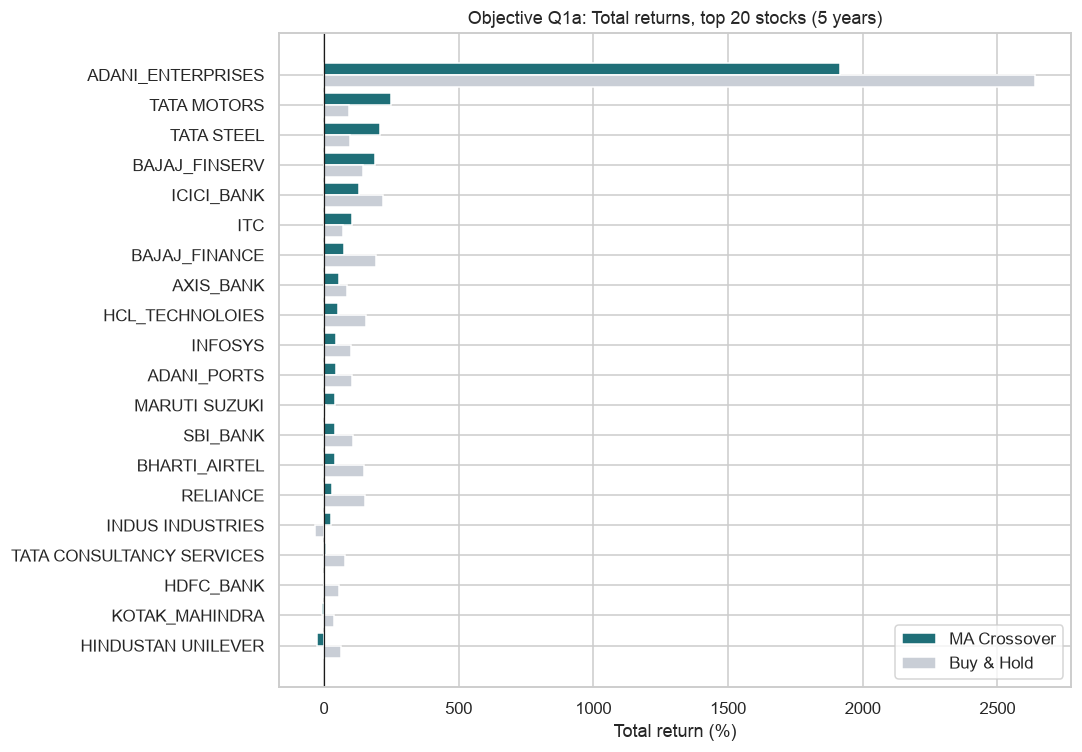

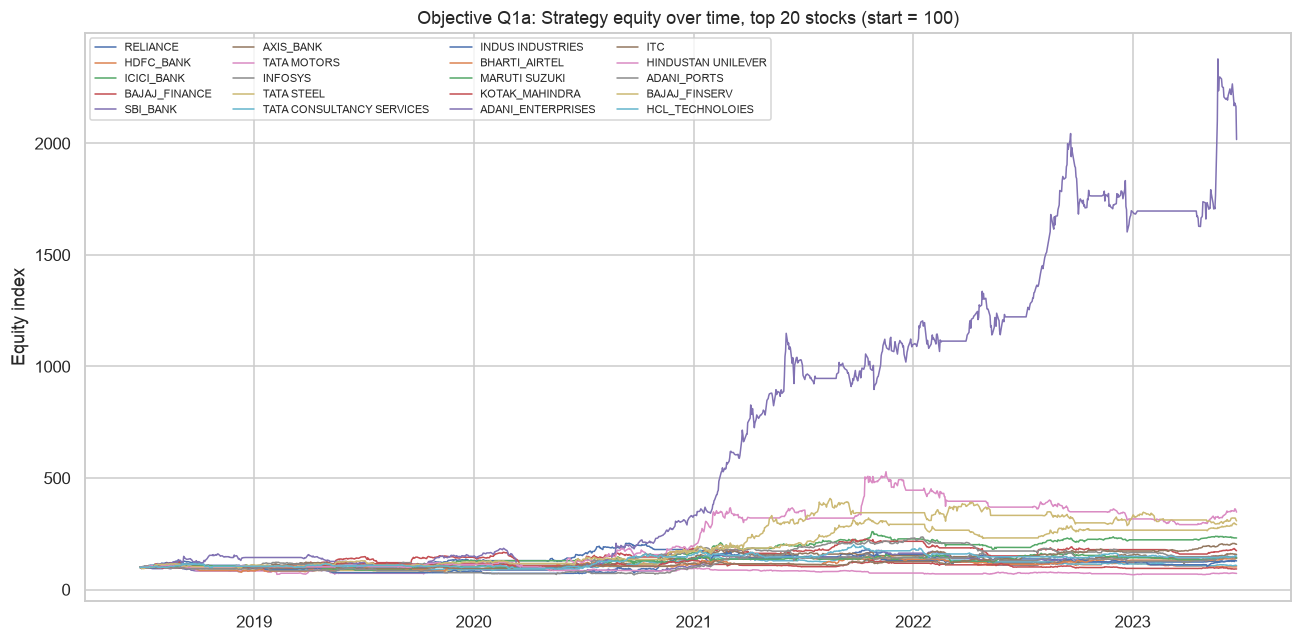

In [9]:
# Objective Q1a: Total returns of the top 20 stocks (strategy vs buy & hold)
m1 = metrics.sort_values("Total_Return_%")
fig, ax = plt.subplots(figsize=(10, 7))
y = np.arange(len(m1))
ax.barh(y + 0.2, m1["Total_Return_%"], 0.4, label="MA Crossover", color="#1F6F78")
ax.barh(y - 0.2, m1["BuyHold_Return_%"], 0.4, label="Buy & Hold", color="#C9CED6")
ax.set_yticks(y); ax.set_yticklabels(m1.index); ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Total return (%)"); ax.set_title("Objective Q1a: Total returns, top 20 stocks (5 years)"); ax.legend()
plt.tight_layout(); plt.savefig("figs/q1a_total_returns.png"); plt.show()

# Total returns over time (rolling equity value for all 20 stocks, indexed to 100)
fig, ax = plt.subplots(figsize=(12, 6))
for s in top20: ax.plot(bt[s].index, bt[s]["Strategy_Equity"] / INITIAL_CAPITAL * 100, lw=1, label=s)
ax.set_title("Objective Q1a: Strategy equity over time, top 20 stocks (start = 100)"); ax.set_ylabel("Equity index")
ax.legend(ncol=4, fontsize=7); plt.tight_layout(); plt.savefig("figs/q1a_equity_over_time.png"); plt.show()

First 5 after sorting: ['ADANI_ENTERPRISES', 'ADANI_PORTS', 'AXIS_BANK', 'BAJAJ_FINANCE', 'BAJAJ_FINSERV']


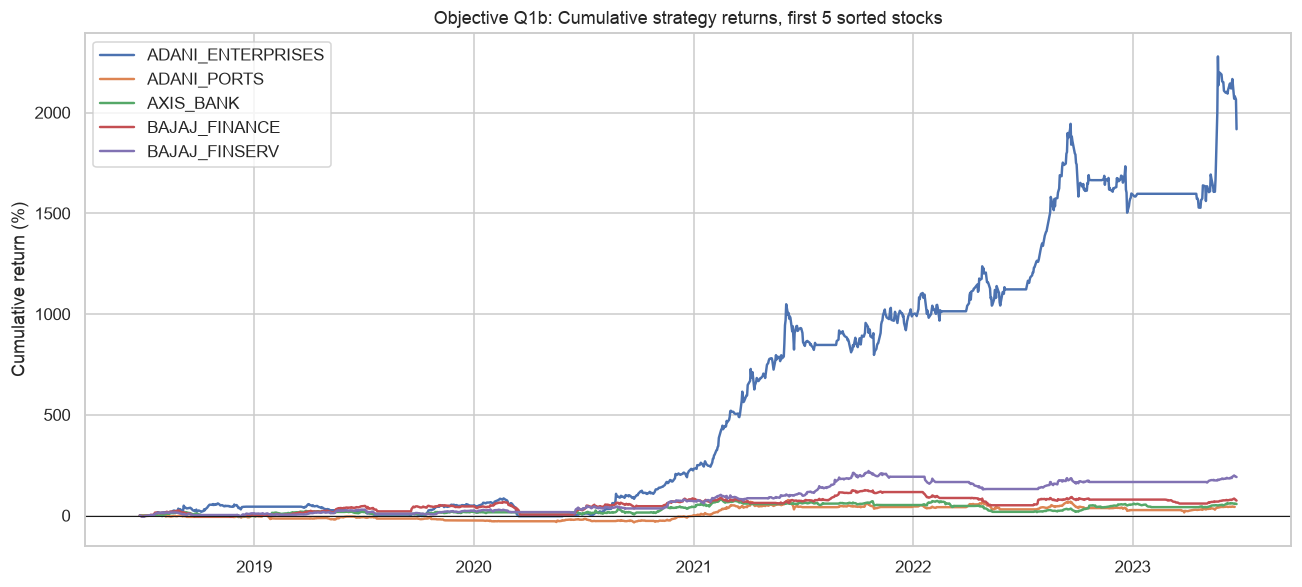

In [10]:
# Objective Q1b: Cumulative returns of the first 5 stocks after alphabetical sorting
first5 = sorted(top20)[:5]
print("First 5 after sorting:", first5)
fig, ax = plt.subplots(figsize=(12, 5.5))
for s in first5: ax.plot(bt[s].index, (bt[s]["Strategy_Equity"] / INITIAL_CAPITAL - 1) * 100, label=s, lw=1.6)
ax.axhline(0, color="k", lw=0.7); ax.set_ylabel("Cumulative return (%)")
ax.set_title("Objective Q1b: Cumulative strategy returns, first 5 sorted stocks"); ax.legend()
plt.tight_layout(); plt.savefig("figs/q1b_cumulative_first5.png"); plt.show()

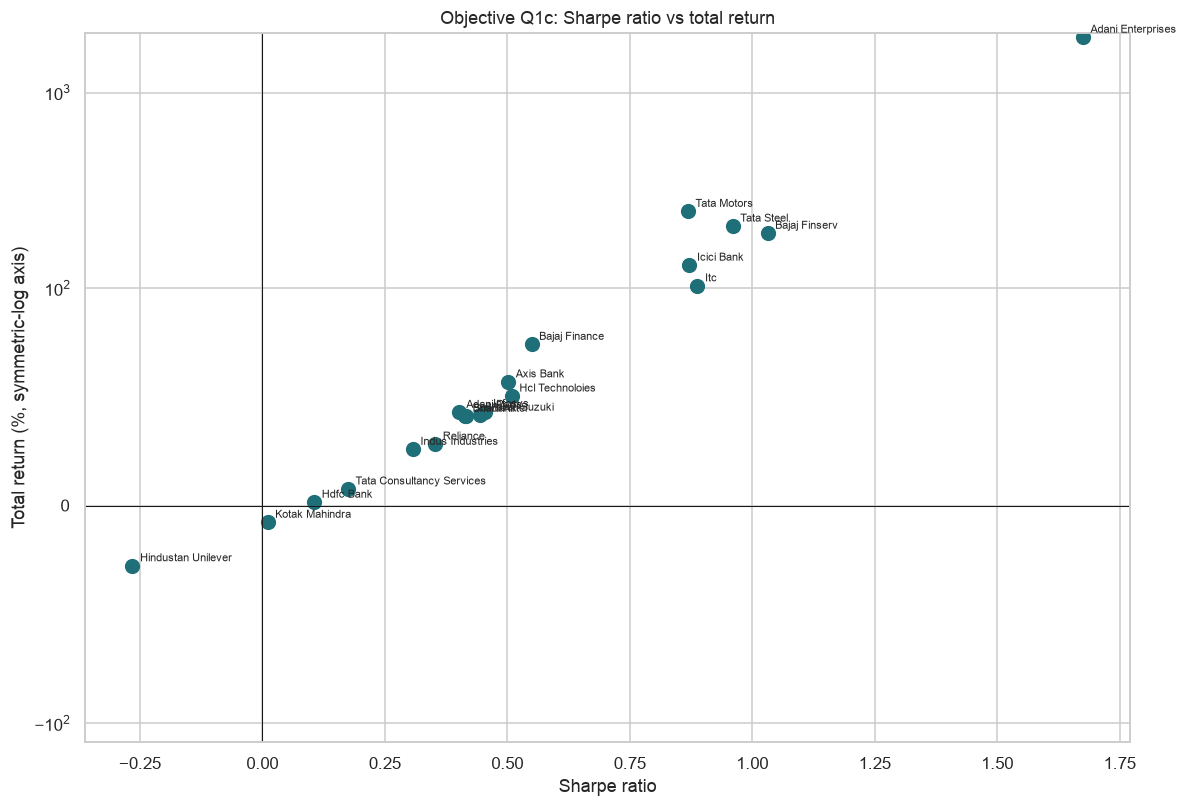

Correlation (Sharpe, Total return): 0.74


In [11]:
# Objective Q1c: Sharpe ratio vs total return (all 20 sorted stocks)
fig, ax = plt.subplots(figsize=(11, 7.5))
ax.scatter(metrics["Sharpe_Ratio"], metrics["Total_Return_%"], s=80, color="#1F6F78")
for s, r in metrics.iterrows(): ax.annotate(s.replace("_"," ").title(), (r["Sharpe_Ratio"], r["Total_Return_%"]), fontsize=7, xytext=(5, 3), textcoords="offset points")
ax.axhline(0, color="k", lw=0.7); ax.axvline(0, color="k", lw=0.7)
ax.set_yscale("symlog", linthresh=100)      # Adani (+1917%) would otherwise squash the other 19 points
ax.set_xlabel("Sharpe ratio"); ax.set_ylabel("Total return (%, symmetric-log axis)"); ax.set_title("Objective Q1c: Sharpe ratio vs total return")
plt.tight_layout(); plt.savefig("figs/q1c_sharpe_vs_return.png"); plt.show()
print("Correlation (Sharpe, Total return): %.2f" % metrics["Sharpe_Ratio"].corr(metrics["Total_Return_%"]))

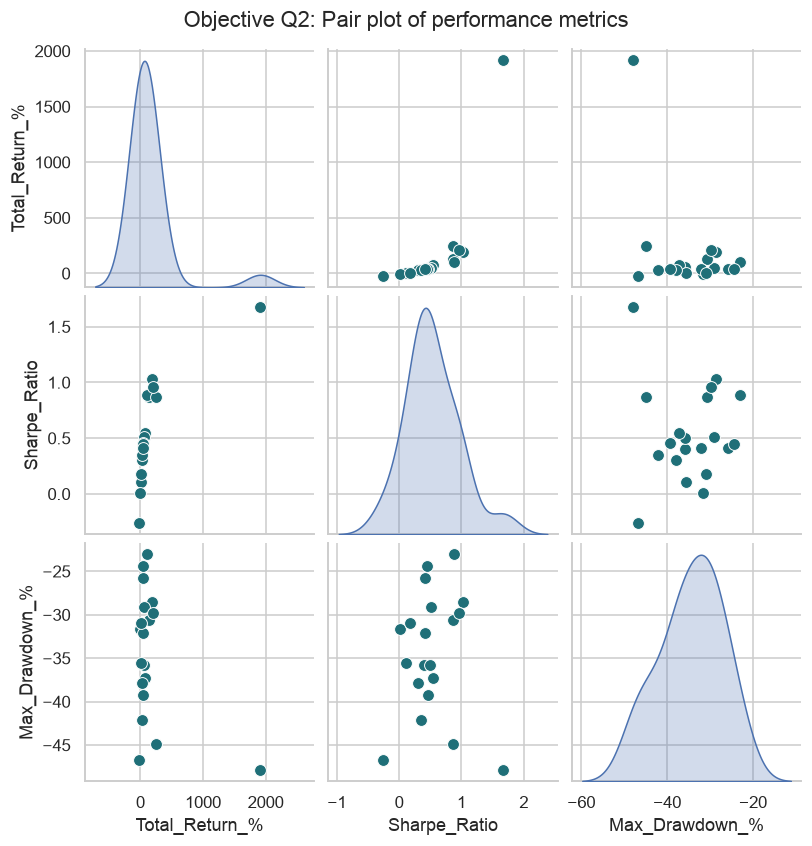

                Total_Return_%  Sharpe_Ratio  Max_Drawdown_%
Total_Return_%            1.00          0.74           -0.42
Sharpe_Ratio              0.74          1.00           -0.01
Max_Drawdown_%           -0.42         -0.01            1.00


In [12]:
# Objective Q2: Pair plot of total return, Sharpe ratio and max drawdown
pp = sns.pairplot(metrics[["Total_Return_%", "Sharpe_Ratio", "Max_Drawdown_%"]], diag_kind="kde", corner=False,
                  plot_kws={"s": 60, "color": "#1F6F78"})
pp.fig.suptitle("Objective Q2: Pair plot of performance metrics", y=1.02)
pp.savefig("figs/q2_pairplot.png"); plt.show()
print(metrics[["Total_Return_%", "Sharpe_Ratio", "Max_Drawdown_%"]].corr().round(2))

In [13]:
# Objective Q3: Highest total return (strategy and buy & hold)
best = metrics["Total_Return_%"].idxmax()
print(f"Highest strategy total return: {best} = {metrics.loc[best,'Total_Return_%']:.1f}%")
bh_best = metrics["BuyHold_Return_%"].idxmax()
print(f"Highest buy & hold return    : {bh_best} = {metrics.loc[bh_best,'BuyHold_Return_%']:.1f}%")
display(metrics["Total_Return_%"].sort_values(ascending=False).head(5).round(1).to_frame())

Highest strategy total return: ADANI_ENTERPRISES = 1917.1%
Highest buy & hold return    : ADANI_ENTERPRISES = 2641.0%


,Total_Return_%
Stock,
ADANI_ENTERPRISES,1917.1
TATA MOTORS,247.2
TATA STEEL,207.8
BAJAJ_FINSERV,191.0
ICICI_BANK,131.3


Lowest strategy max drawdown: ITC = -23.0%
Lowest buy & hold drawdown  : TATA CONSULTANCY SERVICES = -28.2%


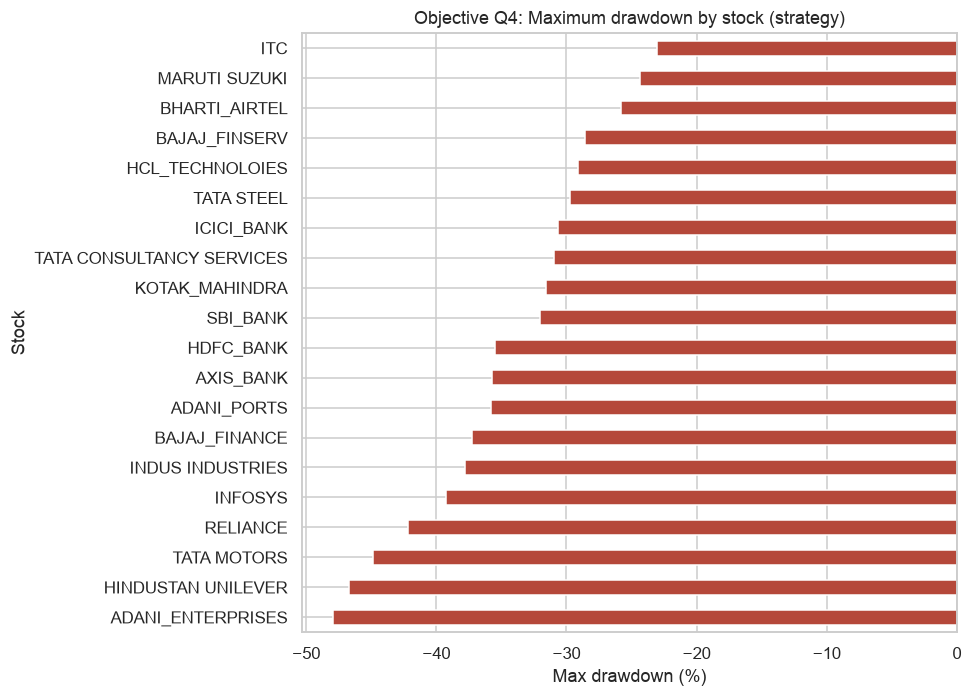

In [14]:
# Objective Q4: Lowest maximum drawdown (strategy; max drawdown is negative, so the highest value = shallowest)
low_dd = metrics["Max_Drawdown_%"].idxmax()
print(f"Lowest strategy max drawdown: {low_dd} = {metrics.loc[low_dd,'Max_Drawdown_%']:.1f}%")
bh_dd = pd.Series({s: (bt[s]["BuyHold_Equity"] / bt[s]["BuyHold_Equity"].cummax() - 1).min() * 100 for s in top20})
print(f"Lowest buy & hold drawdown  : {bh_dd.idxmax()} = {bh_dd.max():.1f}%")
metrics["BuyHold_MaxDD_%"] = bh_dd
fig, ax = plt.subplots(figsize=(9, 6.5))
metrics["Max_Drawdown_%"].sort_values(ascending=False).plot.barh(ax=ax, color="#B5483A")
ax.invert_yaxis(); ax.set_xlabel("Max drawdown (%)"); ax.set_title("Objective Q4: Maximum drawdown by stock (strategy)")
plt.tight_layout(); plt.savefig("figs/q4_drawdown.png"); plt.show()

,Best_Month,Best_Return_%,Worst_Month,Worst_Return_%
ADANI_ENTERPRISES,Jul-2018,72.7,Feb-2023,-54.1
ADANI_PORTS,Feb-2021,32.6,Mar-2020,-26.6
AXIS_BANK,Oct-2022,23.6,Mar-2020,-45.6
BAJAJ_FINANCE,Nov-2020,48.3,Mar-2020,-50.4
BAJAJ_FINSERV,Nov-2020,57.2,Mar-2020,-49.3
BHARTI_AIRTEL,Aug-2021,18.2,Sep-2020,-18.0
HCL_TECHNOLOIES,Jul-2020,26.6,Mar-2020,-18.3
HDFC_BANK,Nov-2020,21.7,Mar-2020,-26.8
HINDUSTAN UNILEVER,Jul-2022,18.2,Oct-2021,-11.4
ICICI_BANK,Nov-2020,20.6,Mar-2020,-34.9


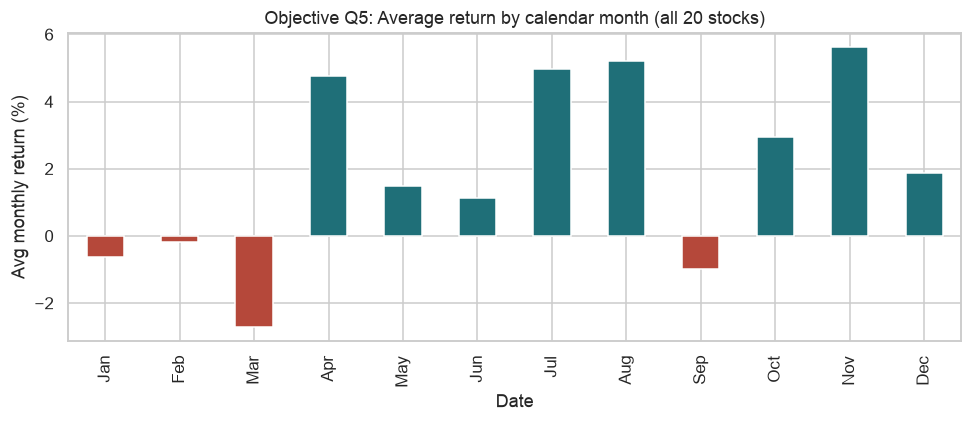

In [15]:
# Objective Q5: Best and worst calendar month (by monthly buy & hold return of the stock) for each stock
monthly = {}
for s in top20:
    m = data[data.Stock == s].set_index("Date")["Close"].resample("ME").last().pct_change().dropna() * 100
    monthly[s] = m
best_worst = pd.DataFrame({s: {"Best_Month": m.idxmax().strftime("%b-%Y"), "Best_Return_%": round(m.max(), 1),
                               "Worst_Month": m.idxmin().strftime("%b-%Y"), "Worst_Return_%": round(m.min(), 1)}
                           for s, m in monthly.items()}).T.sort_index()
display(best_worst)
best_worst.to_csv("outputs/best_worst_months.csv")
# Which calendar month (Jan-Dec) is best on average across stocks?
mm = pd.concat([m.groupby(m.index.month).mean() for m in monthly.values()], axis=1).mean(axis=1)
mm.index = pd.to_datetime(mm.index, format="%m").strftime("%b")
fig, ax = plt.subplots(figsize=(9, 4)); mm.plot.bar(ax=ax, color=["#1F6F78" if v > 0 else "#B5483A" for v in mm])
ax.set_ylabel("Avg monthly return (%)"); ax.set_title("Objective Q5: Average return by calendar month (all 20 stocks)")
plt.tight_layout(); plt.savefig("figs/q5_month_seasonality.png"); plt.show()

,Avg daily volume (million shares)
Stock,
TATA STEEL,113.87
TATA MOTORS,37.35
SBI_BANK,32.00
ICICI_BANK,21.24
ITC,19.73
AXIS_BANK,14.18
BHARTI_AIRTEL,11.85
RELIANCE,9.89
HDFC_BANK,9.09


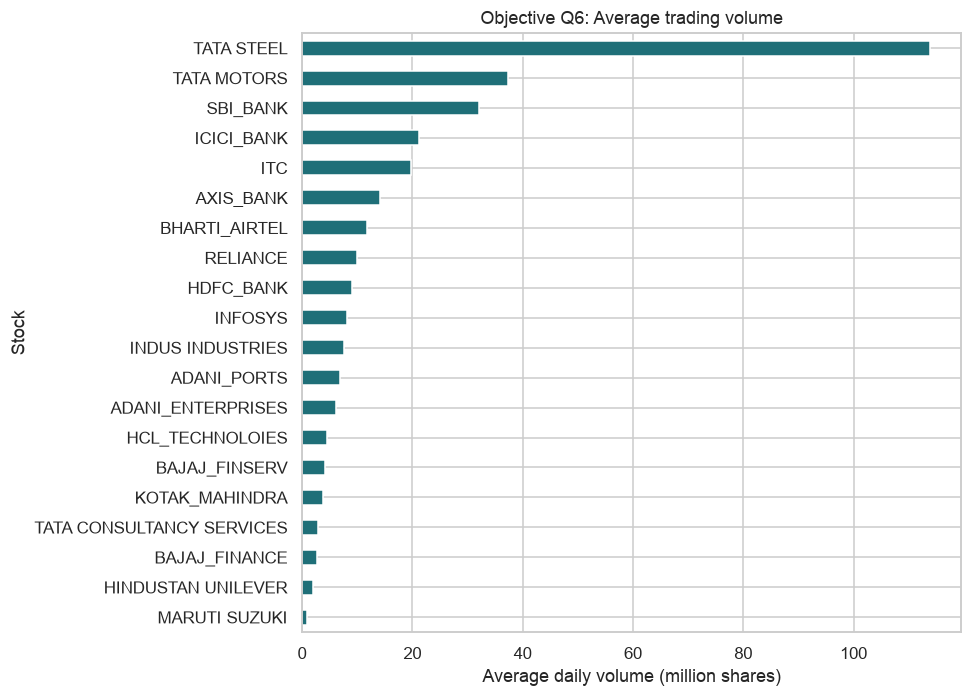

In [16]:
# Objective Q6: Highest average trading volume
avg_vol = data.groupby("Stock")["Volume"].mean().sort_values(ascending=False)
display((avg_vol / 1e6).round(2).head(10).to_frame("Avg daily volume (million shares)"))
fig, ax = plt.subplots(figsize=(9, 6.5)); (avg_vol / 1e6).sort_values().plot.barh(ax=ax, color="#1F6F78")
ax.set_xlabel("Average daily volume (million shares)"); ax.set_title("Objective Q6: Average trading volume")
plt.tight_layout(); plt.savefig("figs/q6_avg_volume.png"); plt.show()

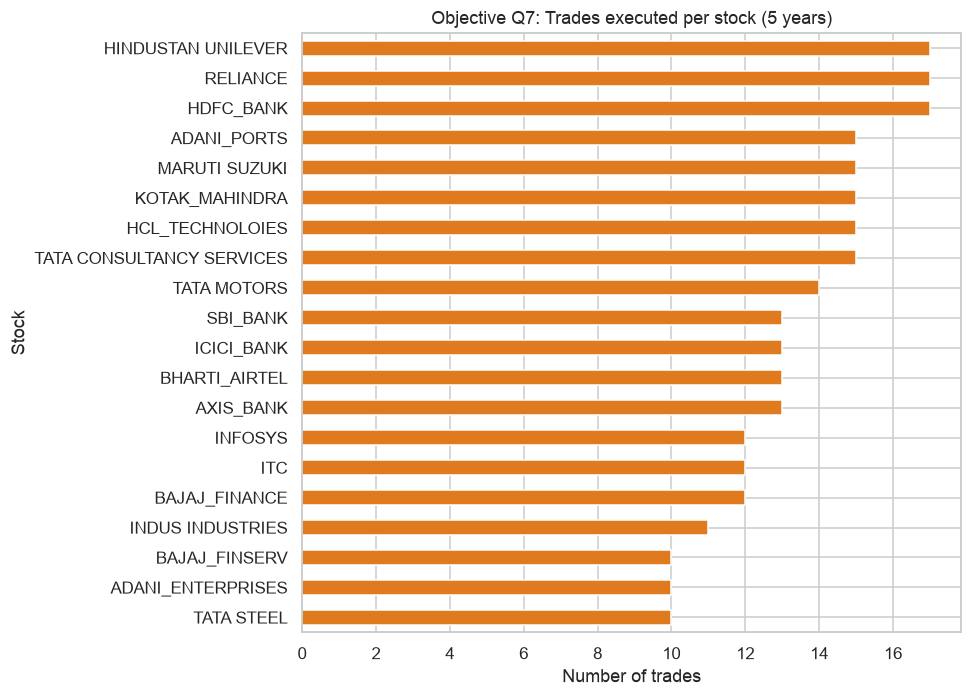

Total trades across 20 stocks: 269 | average per stock: 13.4


,Num_Trades
Stock,
HINDUSTAN UNILEVER,17
RELIANCE,17
HDFC_BANK,17
ADANI_PORTS,15
MARUTI SUZUKI,15
KOTAK_MAHINDRA,15
HCL_TECHNOLOIES,15
TATA CONSULTANCY SERVICES,15
TATA MOTORS,14


In [17]:
# Objective Q7: Number of trades executed per stock
nt = metrics["Num_Trades"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 6.5)); nt.sort_values().plot.barh(ax=ax, color="#E07A1F")
ax.set_xlabel("Number of trades"); ax.set_title("Objective Q7: Trades executed per stock (5 years)")
plt.tight_layout(); plt.savefig("figs/q7_num_trades.png"); plt.show()
print("Total trades across 20 stocks:", int(nt.sum()), "| average per stock: %.1f" % nt.mean())
display(nt.to_frame())

Max single-day LOSS: ADANI_ENTERPRISES on 2023-02-01 = -28.20%
Max single-day GAIN: INDUS INDUSTRIES on 2020-03-26 = 44.67%


,Max_Daily_Loss_%,Max_Daily_Gain_%
Stock,,
ADANI_ENTERPRISES,-28.20,27.37
ADANI_PORTS,-19.18,12.57
AXIS_BANK,-27.91,19.48
BAJAJ_FINANCE,-23.23,10.97
BAJAJ_FINSERV,-25.86,11.45
BHARTI_AIRTEL,-11.95,11.29
HCL_TECHNOLOIES,-8.56,11.18
HDFC_BANK,-12.61,11.60
HINDUSTAN UNILEVER,-8.87,13.50


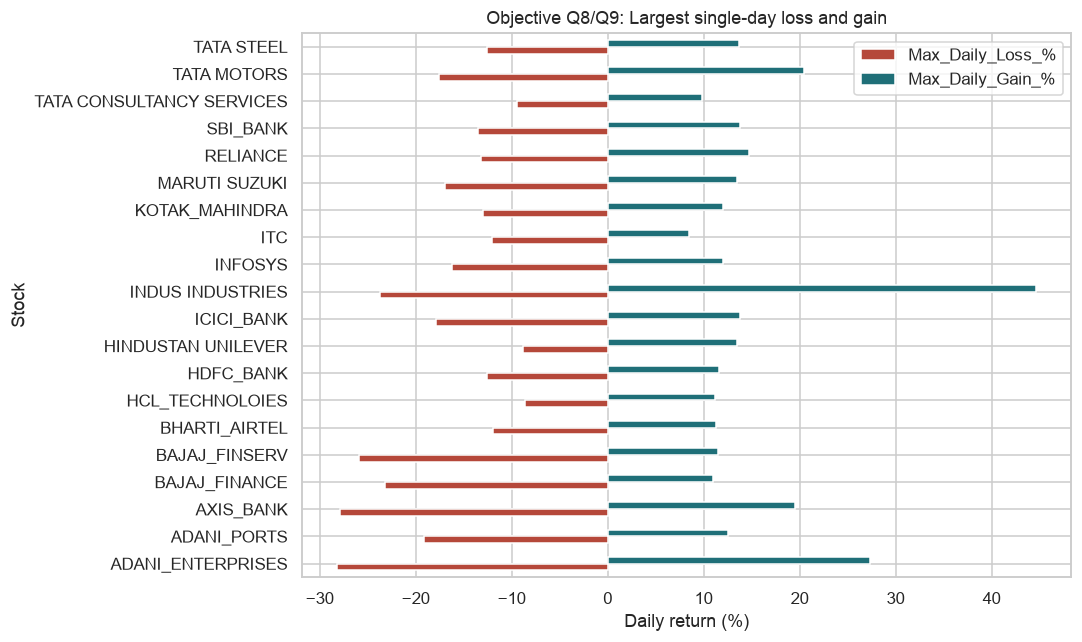

In [18]:
# Objective Q8 and Q9: Max single-day loss and gain
dr = data.dropna(subset=["Daily_Return"])
worst = dr.loc[dr["Daily_Return"].idxmin()]; bestd = dr.loc[dr["Daily_Return"].idxmax()]
print(f"Max single-day LOSS: {worst.Stock} on {worst.Date.date()} = {worst.Daily_Return*100:.2f}%")
print(f"Max single-day GAIN: {bestd.Stock} on {bestd.Date.date()} = {bestd.Daily_Return*100:.2f}%")
ext = pd.DataFrame({"Max_Daily_Loss_%": dr.groupby("Stock")["Daily_Return"].min() * 100,
                    "Max_Daily_Gain_%": dr.groupby("Stock")["Daily_Return"].max() * 100}).sort_index()
display(ext.round(2))
fig, ax = plt.subplots(figsize=(10, 6)); ext.plot.barh(ax=ax, color=["#B5483A", "#1F6F78"])
ax.set_title("Objective Q8/Q9: Largest single-day loss and gain"); ax.set_xlabel("Daily return (%)")
plt.tight_layout(); plt.savefig("figs/q8q9_extremes.png"); plt.show()

,Avg Close (Rs)
Stock,
TATA STEEL,77.27
ITC,260.38
TATA MOTORS,283.71
SBI_BANK,376.67
BHARTI_AIRTEL,547.94


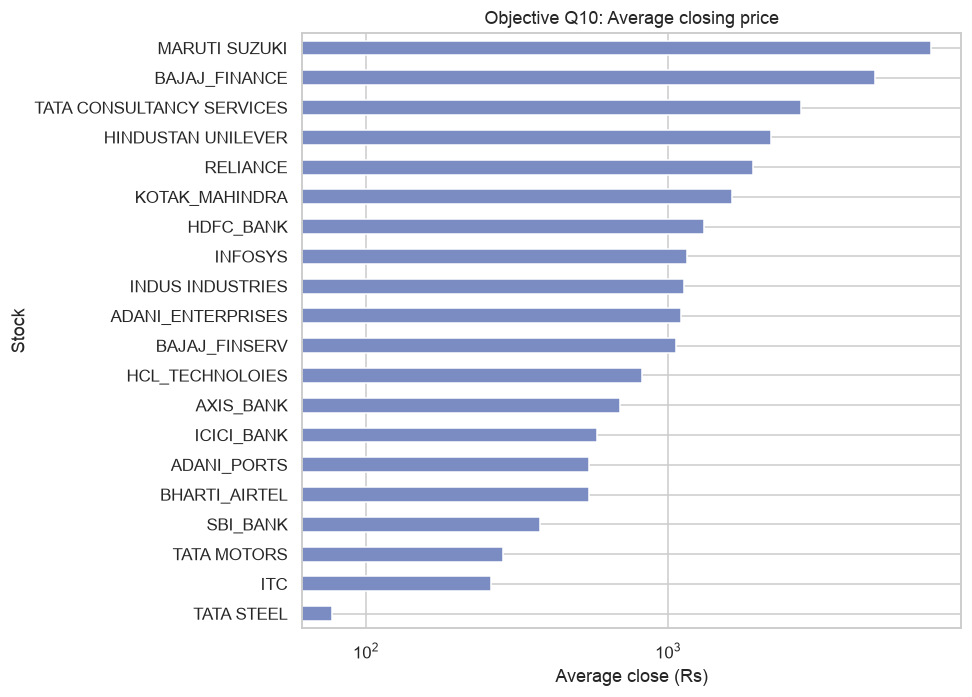

In [19]:
# Objective Q10: Lowest average closing price
avg_close = data.groupby("Stock")["Close"].mean().sort_values()
display(avg_close.round(2).head(5).to_frame("Avg Close (Rs)"))
fig, ax = plt.subplots(figsize=(9, 6.5)); avg_close.plot.barh(ax=ax, color="#7A8CC2")
ax.set_xlabel("Average close (Rs)"); ax.set_title("Objective Q10: Average closing price"); ax.set_xscale("log")
plt.tight_layout(); plt.savefig("figs/q10_avg_close.png"); plt.show()

# Subjective Questions

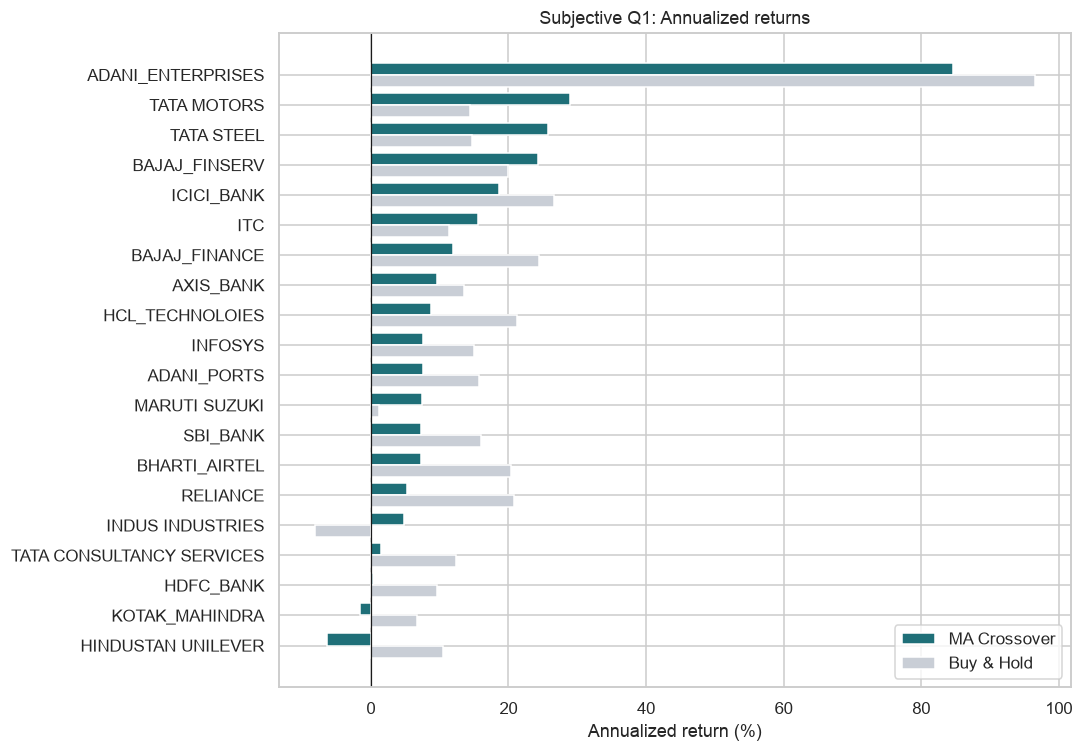

Mean annualized (strategy): 13.47% | median: 7.61% | stocks positive: 18/20
Mean annualized (buy & hold): 18.15% | strategy beat buy&hold in 6/20 stocks


In [20]:
# Subjective Q1: Annualized returns across stocks
ann = metrics[["Annualized_Return_%"]].copy()
ann["BuyHold_Annualized_%"] = ((1 + metrics["BuyHold_Return_%"] / 100) ** (TRADING_DAYS / len(bt[top20[0]])) - 1) * 100
ann = ann.sort_values("Annualized_Return_%")
fig, ax = plt.subplots(figsize=(10, 7)); y = np.arange(len(ann))
ax.barh(y + 0.2, ann["Annualized_Return_%"], 0.4, label="MA Crossover", color="#1F6F78")
ax.barh(y - 0.2, ann["BuyHold_Annualized_%"], 0.4, label="Buy & Hold", color="#C9CED6")
ax.set_yticks(y); ax.set_yticklabels(ann.index); ax.axvline(0, color="k", lw=0.8); ax.legend()
ax.set_xlabel("Annualized return (%)"); ax.set_title("Subjective Q1: Annualized returns")
plt.tight_layout(); plt.savefig("figs/s1_annualized.png"); plt.show()
print("Mean annualized (strategy): %.2f%% | median: %.2f%% | stocks positive: %d/20" % (
    ann["Annualized_Return_%"].mean(), ann["Annualized_Return_%"].median(), (ann["Annualized_Return_%"] > 0).sum()))
print("Mean annualized (buy & hold): %.2f%% | strategy beat buy&hold in %d/20 stocks" % (
    ann["BuyHold_Annualized_%"].mean(), (ann["Annualized_Return_%"] > ann["BuyHold_Annualized_%"]).sum()))

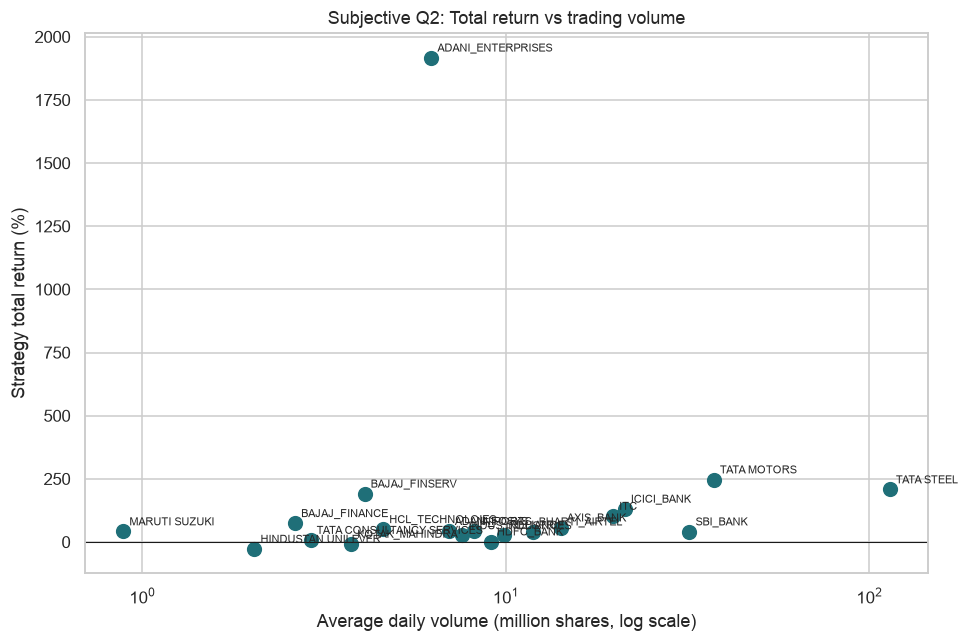

Pearson: 0.02 | Spearman (strategy): 0.40 | Spearman (buy&hold): 0.17


In [21]:
# Subjective Q2: Total return vs trading volume
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(metrics["Avg_Daily_Volume"] / 1e6, metrics["Total_Return_%"], s=80, color="#1F6F78")
for s, r in metrics.iterrows(): ax.annotate(s, (r["Avg_Daily_Volume"] / 1e6, r["Total_Return_%"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.set_xscale("log"); ax.axhline(0, color="k", lw=0.7)
ax.set_xlabel("Average daily volume (million shares, log scale)"); ax.set_ylabel("Strategy total return (%)")
ax.set_title("Subjective Q2: Total return vs trading volume")
plt.tight_layout(); plt.savefig("figs/s2_return_vs_volume.png"); plt.show()
pear = metrics["Avg_Daily_Volume"].corr(metrics["Total_Return_%"])
spear = metrics["Avg_Daily_Volume"].corr(metrics["Total_Return_%"], method="spearman")
pear_bh = metrics["Avg_Daily_Volume"].corr(metrics["BuyHold_Return_%"], method="spearman")
print(f"Pearson: {pear:.2f} | Spearman (strategy): {spear:.2f} | Spearman (buy&hold): {pear_bh:.2f}")

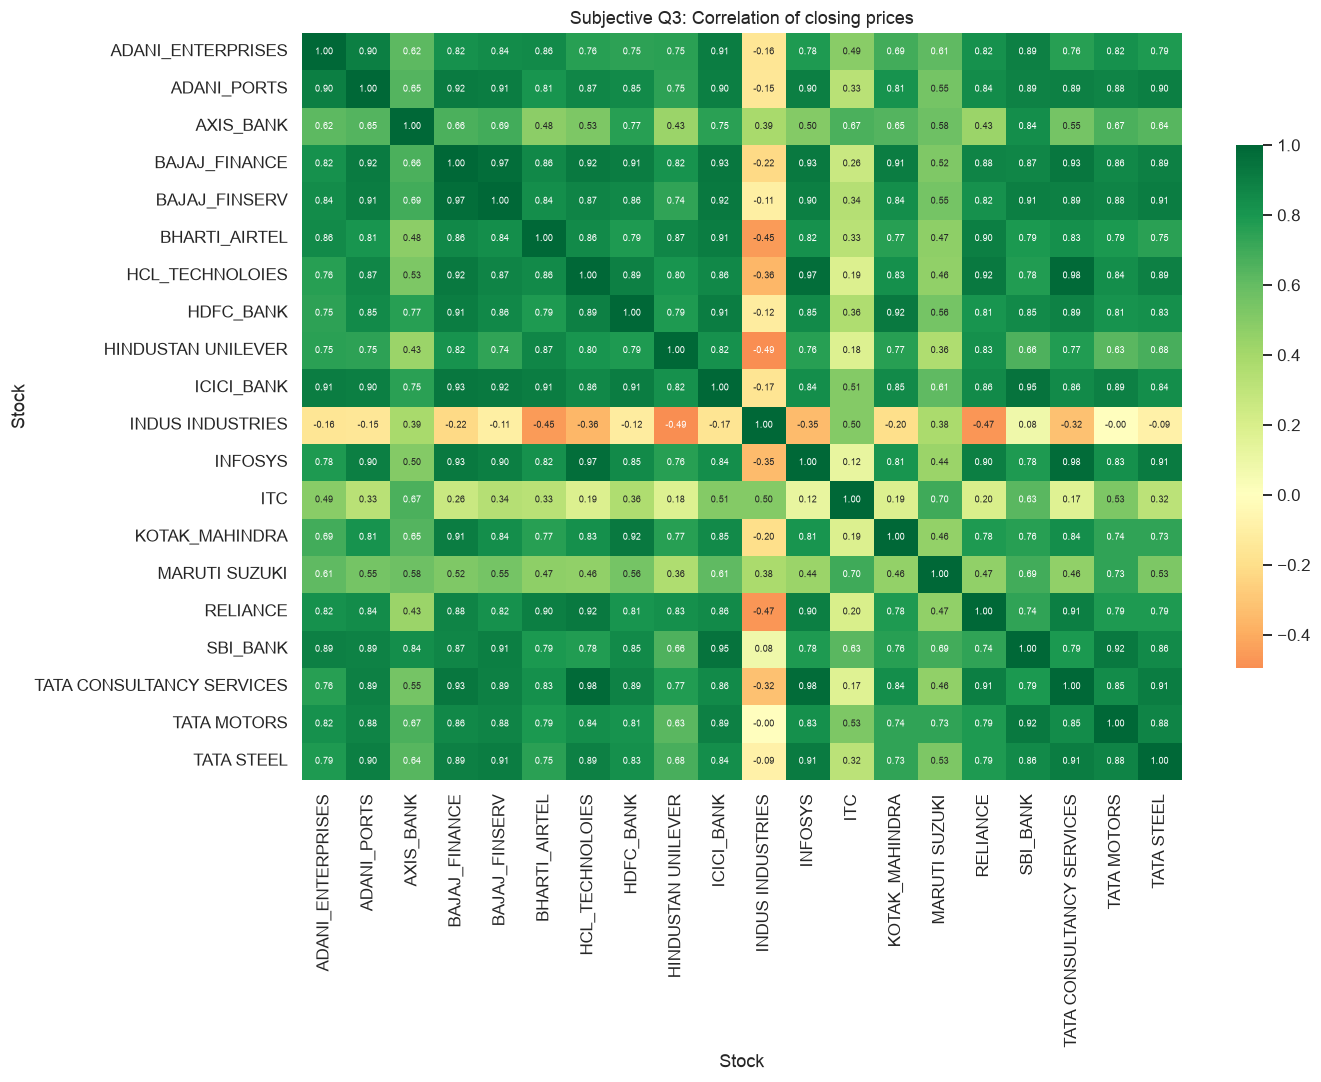

Most correlated pairs:


corr
Stock           Stock                           
HCL_TECHNOLOIES TATA CONSULTANCY SERVICES  0.983
INFOSYS         TATA CONSULTANCY SERVICES  0.982
BAJAJ_FINANCE   BAJAJ_FINSERV              0.972
HCL_TECHNOLOIES INFOSYS                    0.969
ICICI_BANK      SBI_BANK                   0.948
BAJAJ_FINANCE   TATA CONSULTANCY SERVICES  0.933
                ICICI_BANK                 0.930
                INFOSYS                    0.926

Least correlated pairs:


corr
Stock      Stock                          
TATA STEEL RELIANCE                    NaN
           SBI_BANK                    NaN
           TATA CONSULTANCY SERVICES   NaN
           TATA MOTORS                 NaN
           TATA STEEL                  NaN

Most correlated pairs on DAILY RETURNS (diversification view):


,,corr
Stock,Stock,
BAJAJ_FINANCE,BAJAJ_FINSERV,0.827
AXIS_BANK,ICICI_BANK,0.736
ICICI_BANK,SBI_BANK,0.685
AXIS_BANK,SBI_BANK,0.633
HCL_TECHNOLOIES,INFOSYS,0.627


Average price correlation of each stock with the rest:


,avg corr
Stock,
ICICI_BANK,0.79
SBI_BANK,0.77
BAJAJ_FINANCE,0.77
BAJAJ_FINSERV,0.77
ADANI_PORTS,0.76


In [22]:
# Subjective Q3: Correlation heatmap of closing prices
close_wide = data.pivot(index="Date", columns="Stock", values="Close")
corr = close_wide.corr()
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlGn", center=0, annot_kws={"size": 6}, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Subjective Q3: Correlation of closing prices"); plt.tight_layout(); plt.savefig("figs/s3_heatmap.png"); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print("Most correlated pairs:"); display(pairs.head(8).round(3).to_frame("corr"))
print("Least correlated pairs:"); display(pairs.tail(5).round(3).to_frame("corr"))
ret_corr = close_wide.pct_change().corr()
rp = ret_corr.where(np.triu(np.ones(ret_corr.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print("Most correlated pairs on DAILY RETURNS (diversification view):"); display(rp.head(5).round(3).to_frame("corr"))
print("Average price correlation of each stock with the rest:"); display(((corr.sum() - 1) / 19).sort_values(ascending=False).round(2).head(5).to_frame("avg corr"))

,Total_Return_%,Annualized_Return_%,Max_Drawdown_%,Sharpe_Ratio,Win_Loss_Ratio,Win_Rate_%,Num_Trades,BuyHold_Return_%
Stock,,,,,,,,
ADANI_ENTERPRISES,1917.15,84.60,-47.92,1.67,1.50,60.00,10,2641.03
BAJAJ_FINSERV,191.02,24.35,-28.54,1.03,4.00,80.00,10,143.60
TATA STEEL,207.83,25.79,-29.77,0.96,0.67,40.00,10,96.20
ITC,102.93,15.53,-23.04,0.89,1.40,58.33,12,69.36
ICICI_BANK,131.29,18.66,-30.65,0.87,1.17,53.85,13,218.78
TATA MOTORS,247.16,28.91,-44.89,0.87,0.56,35.71,14,93.38
BAJAJ_FINANCE,74.24,12.00,-37.27,0.55,1.40,58.33,12,192.38
HCL_TECHNOLOIES,50.46,8.69,-29.13,0.51,0.88,46.67,15,156.39
AXIS_BANK,56.98,9.64,-35.75,0.50,0.86,46.15,13,86.02


Portfolio-level (equal weight) summary:
MA Crossover (equal weight)    total 97.4% | ann 14.9% | maxDD -17.4% | Sharpe 1.22
Buy & Hold (equal weight)      total 162.7% | ann 21.8% | maxDD -43.3% | Sharpe 0.99


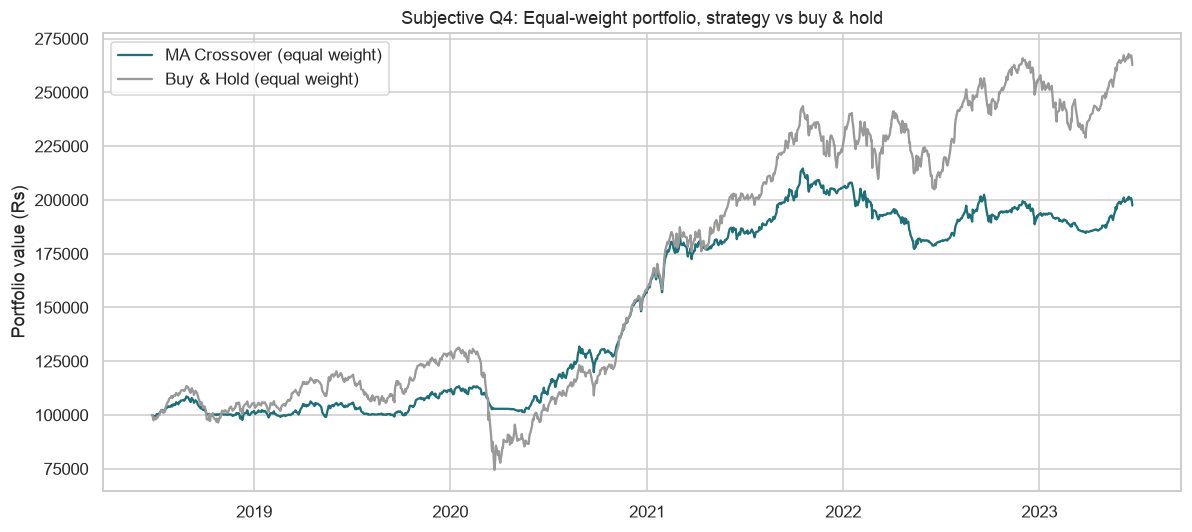

In [23]:
# Subjective Q4: Consolidated backtest scorecard
cols = ["Total_Return_%", "Annualized_Return_%", "Max_Drawdown_%", "Sharpe_Ratio", "Win_Loss_Ratio", "Win_Rate_%", "Num_Trades", "BuyHold_Return_%"]
score = metrics[cols].copy().replace(np.inf, np.nan)
display(score.sort_values("Sharpe_Ratio", ascending=False).round(2))
print("Portfolio-level (equal weight) summary:")
eq = pd.concat([bt[s]["Strategy_Return"].fillna(0) for s in top20], axis=1).mean(axis=1)
eqb = pd.concat([bt[s]["Daily_Return"].fillna(0) for s in top20], axis=1).mean(axis=1)
for name, r in [("MA Crossover (equal weight)", eq), ("Buy & Hold (equal weight)", eqb)]:
    e = INITIAL_CAPITAL * (1 + r).cumprod()
    mm_ = compute_metrics(e, r, pd.DataFrame({"Return": [1]}))
    print(f"{name:30s} total {mm_['Total_Return_%']:.1f}% | ann {mm_['Annualized_Return_%']:.1f}% | maxDD {mm_['Max_Drawdown_%']:.1f}% | Sharpe {mm_['Sharpe_Ratio']:.2f}")
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot((INITIAL_CAPITAL * (1 + eq).cumprod()), label="MA Crossover (equal weight)", color="#1F6F78")
ax.plot((INITIAL_CAPITAL * (1 + eqb).cumprod()), label="Buy & Hold (equal weight)", color="#999")
ax.set_title("Subjective Q4: Equal-weight portfolio, strategy vs buy & hold"); ax.set_ylabel("Portfolio value (Rs)"); ax.legend()
plt.tight_layout(); plt.savefig("figs/s4_portfolio.png"); plt.show()
port_summary = {n: compute_metrics(INITIAL_CAPITAL * (1 + r).cumprod(), r, pd.DataFrame({"Return": [1]})) for n, r in [("strategy", eq), ("buyhold", eqb)]}

,Score,Total_Return_%,Annualized_Return_%,Max_Drawdown_%,Sharpe_Ratio,Win_Rate_%,Num_Trades
Stock,,,,,,,
BAJAJ_FINSERV,90.0,191.02,24.35,-28.54,1.03,80.00,10
ITC,86.0,102.93,15.53,-23.04,0.89,58.33,12
TATA STEEL,80.2,207.83,25.79,-29.77,0.96,40.00,10
ICICI_BANK,77.2,131.29,18.66,-30.65,0.87,53.85,13
ADANI_ENTERPRISES,75.8,1917.15,84.60,-47.92,1.67,60.00,10
HCL_TECHNOLOIES,66.2,50.46,8.69,-29.13,0.51,46.67,15
BAJAJ_FINANCE,63.0,74.24,12.00,-37.27,0.55,58.33,12
MARUTI SUZUKI,61.7,41.66,7.37,-24.36,0.44,53.33,15
TATA MOTORS,60.5,247.16,28.91,-44.89,0.87,35.71,14


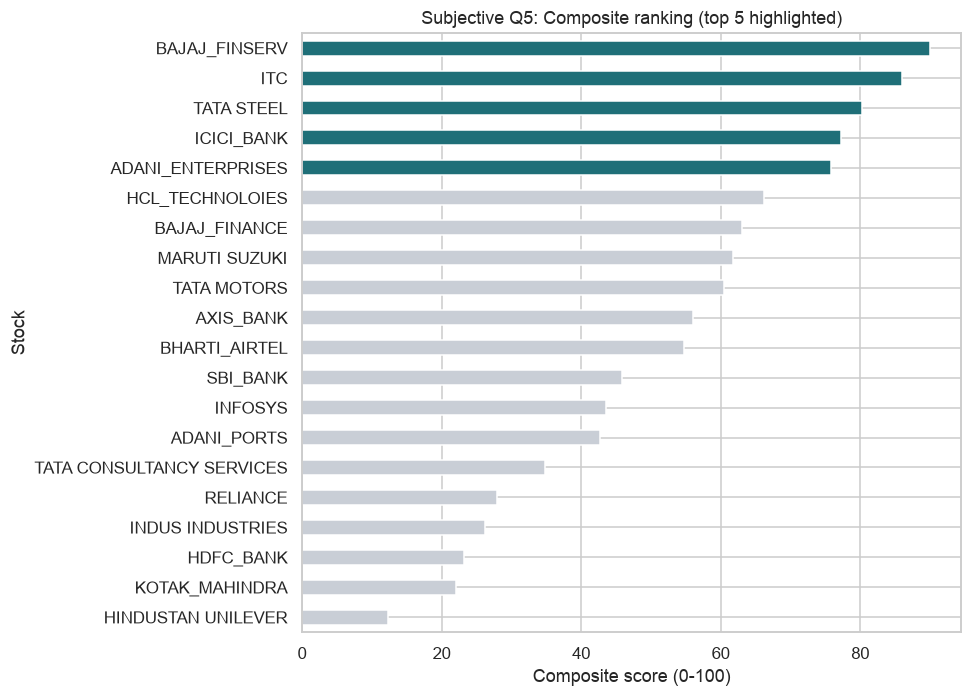

RECOMMENDED: ['BAJAJ_FINSERV', 'ITC', 'TATA STEEL', 'ICICI_BANK', 'ADANI_ENTERPRISES']
AVOID (profitable only if bought and held, or loss-making): ['RELIANCE', 'INDUS INDUSTRIES', 'HDFC_BANK', 'KOTAK_MAHINDRA', 'HINDUSTAN UNILEVER']


In [24]:
# Subjective Q5: Recommendation - composite ranking of the stocks
rank = pd.DataFrame(index=metrics.index)
rank["R_Sharpe"] = metrics["Sharpe_Ratio"].rank(ascending=False)
rank["R_Return"] = metrics["Annualized_Return_%"].rank(ascending=False)
rank["R_DD"] = metrics["Max_Drawdown_%"].rank(ascending=False)
rank["R_WinRate"] = metrics["Win_Rate_%"].rank(ascending=False)
# weights: Sharpe 35%, annualized return 30%, drawdown 25%, win rate 10%
rank["Score"] = 0.35 * (21 - rank["R_Sharpe"]) + 0.30 * (21 - rank["R_Return"]) + 0.25 * (21 - rank["R_DD"]) + 0.10 * (21 - rank["R_WinRate"])
rank["Score"] = (rank["Score"] / 20 * 100).round(1)
rec = rank.join(metrics[["Total_Return_%", "Annualized_Return_%", "Max_Drawdown_%", "Sharpe_Ratio", "Win_Rate_%", "Num_Trades", "BuyHold_Return_%"]]).sort_values("Score", ascending=False)
display(rec[["Score", "Total_Return_%", "Annualized_Return_%", "Max_Drawdown_%", "Sharpe_Ratio", "Win_Rate_%", "Num_Trades"]].round(2))
rec.round(3).to_csv("outputs/recommendation_ranking.csv")
fig, ax = plt.subplots(figsize=(9, 6.5))
rec["Score"].sort_values().plot.barh(ax=ax, color=["#1F6F78" if i in rec.index[:5] else "#C9CED6" for i in rec["Score"].sort_values().index])
ax.set_xlabel("Composite score (0-100)"); ax.set_title("Subjective Q5: Composite ranking (top 5 highlighted)")
plt.tight_layout(); plt.savefig("figs/s5_ranking.png"); plt.show()
print("RECOMMENDED:", rec.index[:5].tolist())
print("AVOID (profitable only if bought and held, or loss-making):", rec.index[-5:].tolist())

## Conclusion
See the accompanying Word report and presentation for the full narrative. Key caveats: results ignore brokerage, taxes and slippage; MA crossovers lag price and generate whipsaw losses in sideways markets; five years that include the 2020 crash and a strong recovery are a short sample.